# 🚗 Car Price Prediction with Machine Learning
## Project Overview
Used-car pricing is hard because many factors interact: age, mileage, fuel type, ownership history and more. This project builds a regression model that predicts a car's **selling price** from its features.

## Objectives
1. Explore and clean the dataset
2. Engineer features that capture price drivers
3. Train and compare several regression models
4. Evaluate performance and interpret the results

## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    cross_validate,
    KFold,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)
from sklearn.inspection import permutation_importance
import joblib
import warnings
from datetime import datetime
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")

All libraries imported successfully.


##  Data Loading, Inspecting And Cleaning 

In [2]:
car_data = pd.read_csv("car data.csv")

In [3]:
car_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 30.0 KB


In [4]:
car_data.head(20)

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.350,5.590,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.750,9.540,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.250,9.850,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.850,4.150,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.600,6.870,42450,Diesel,Dealer,Manual,0
5,vitara brezza,2018,9.250,9.830,2071,Diesel,Dealer,Manual,0
6,ciaz,2015,6.750,8.120,18796,Petrol,Dealer,Manual,0
7,s cross,2015,6.500,8.610,33429,Diesel,Dealer,Manual,0
8,ciaz,2016,8.750,8.890,20273,Diesel,Dealer,Manual,0
9,ciaz,2015,7.450,8.920,42367,Diesel,Dealer,Manual,0


In [5]:
car_data.tail(20)

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
281,city,2006,2.100,7.600,50456,Petrol,Dealer,Manual,0
282,city,2014,8.250,14.000,63000,Diesel,Dealer,Manual,0
283,city,2016,8.990,11.800,9010,Petrol,Dealer,Manual,0
284,brio,2013,3.500,5.900,9800,Petrol,Dealer,Manual,0
285,jazz,2016,7.400,8.500,15059,Petrol,Dealer,Automatic,0
286,jazz,2016,5.650,7.900,28569,Petrol,Dealer,Manual,0
287,amaze,2015,5.750,7.500,44000,Petrol,Dealer,Automatic,0
288,city,2015,8.400,13.600,34000,Petrol,Dealer,Manual,0
289,city,2016,10.110,13.600,10980,Petrol,Dealer,Manual,0
290,amaze,2014,4.500,6.400,19000,Petrol,Dealer,Manual,0


In [6]:
car_data.columns.tolist()

['Car_Name',
 'Year',
 'Selling_Price',
 'Present_Price',
 'Driven_kms',
 'Fuel_Type',
 'Selling_type',
 'Transmission',
 'Owner']

In [7]:
print("Duplicates:", car_data.duplicated().sum())

Duplicates: 2


##  Exploratory Data Analysis(EDA)

In [8]:
print(car_data.nunique().sort_values())
for col in ["Owner", "Fuel_Type", "Selling_type", "Transmission"]:
    print(f"\n{col}:\n{car_data[col].value_counts(normalize=True).round(3)}")

Selling_type       2
Transmission       2
Fuel_Type          3
Owner              3
Year              16
Car_Name          98
Present_Price    148
Selling_Price    156
Driven_kms       206
dtype: int64

Owner:
Owner
0   0.963
1   0.033
3   0.003
Name: proportion, dtype: float64

Fuel_Type:
Fuel_Type
Petrol   0.794
Diesel   0.199
CNG      0.007
Name: proportion, dtype: float64

Selling_type:
Selling_type
Dealer       0.648
Individual   0.352
Name: proportion, dtype: float64

Transmission:
Transmission
Manual      0.867
Automatic   0.133
Name: proportion, dtype: float64


In [9]:
car_data["Is_Bike"] = car_data["Car_Name"].str[0].str.isupper()
print(car_data["Is_Bike"].value_counts())
print(car_data.groupby("Is_Bike")[["Selling_Price", "Present_Price", "Driven_kms"]].median())

Is_Bike
False    200
True     101
Name: count, dtype: int64
         Selling_Price  Present_Price  Driven_kms
Is_Bike                                          
False            5.250          8.450   40000.000
True             0.500          0.840   18000.000


In [10]:
car_data = car_data.drop_duplicates(keep="first").reset_index(drop=True)

In [11]:
print(car_data.select_dtypes("number").corr()["Selling_Price"].sort_values(ascending=False))

Selling_Price    1.000
Present_Price    0.876
Year             0.234
Driven_kms       0.029
Owner           -0.088
Name: Selling_Price, dtype: float64


In [12]:
for col in ["Fuel_Type", "Transmission", "Selling_type", "Owner"]:
    print(f"\n{car_data.groupby(col)['Selling_Price'].agg(['count','mean','median'])}")


           count   mean  median
Fuel_Type                      
CNG            2  3.100   3.100
Diesel        58 10.103   7.600
Petrol       239  3.264   2.650

              count  mean  median
Transmission                     
Automatic        39 9.072   5.750
Manual          260 3.917   3.250

              count  mean  median
Selling_type                     
Dealer          193 6.632   5.250
Individual      106 0.871   0.515

       count  mean  median
Owner                     
0        288 4.688   3.700
1         10 1.970   0.800
3          1 2.500   2.500


In [13]:
print(car_data[car_data["Is_Bike"]]["Car_Name"].unique())      
print(car_data[~car_data["Is_Bike"]]["Car_Name"].unique())

<ArrowStringArray>
['Royal Enfield Thunder 500',        'UM Renegade Mojave',
                 'KTM RC200',         'Bajaj Dominar 400',
 'Royal Enfield Classic 350',                 'KTM RC390',
            'Hyosung GT250R', 'Royal Enfield Thunder 350',
             'KTM 390 Duke ',       'Mahindra Mojo XT300',
        'Bajaj Pulsar RS200',  'Royal Enfield Bullet 350',
 'Royal Enfield Classic 500',         'Bajaj Avenger 220',
         'Bajaj Avenger 150',      'Honda CB Hornet 160R',
         'Yamaha FZ S V 2.0',              'Yamaha FZ 16',
        'TVS Apache RTR 160',          'Bajaj Pulsar 150',
             'Honda CBR 150',              'Hero Extreme',
    'Bajaj Avenger 220 dtsi',  'Bajaj Avenger 150 street',
          'Yamaha FZ  v 2.0',      'Bajaj Pulsar  NS 200',
        'Bajaj Pulsar 220 F',        'TVS Apache RTR 180',
        'Hero Passion X pro',       'Bajaj Pulsar NS 200',
             'Yamaha Fazer ',           'Honda Activa 4G',
                'TVS Sport ',        

In [14]:
all_vehicles = car_data.copy()
car_data = car_data[~car_data["Is_Bike"]].drop(columns="Is_Bike").reset_index(drop=True)
print("Cars only:", car_data.shape)

Cars only: (198, 9)


In [15]:
print(car_data.select_dtypes("number").corr()["Selling_Price"].sort_values(ascending=False))
for col in ["Fuel_Type", "Transmission", "Selling_type", "Owner"]:
    print(f"\n{car_data.groupby(col)['Selling_Price'].agg(['count','mean','median'])}")

Selling_Price    1.000
Present_Price    0.821
Year             0.349
Owner           -0.085
Driven_kms      -0.112
Name: Selling_Price, dtype: float64

           count   mean  median
Fuel_Type                      
CNG            2  3.100   3.100
Diesel        58 10.103   7.600
Petrol       138  5.184   4.700

              count   mean  median
Transmission                      
Automatic        30 11.688   7.625
Manual          168  5.696   4.925

              count  mean  median
Selling_type                     
Dealer          193 6.632   5.250
Individual        5 5.520   2.750

       count  mean  median
Owner                     
0        193 6.672   5.250
1          4 4.338   4.425
3          1 2.500   2.500


In [16]:
for col in ["Selling_type", "Owner"]:
    print(car_data[col].value_counts(normalize=True).round(3), "\n")

Selling_type
Dealer       0.975
Individual   0.025
Name: proportion, dtype: float64 

Owner
0   0.975
1   0.020
3   0.005
Name: proportion, dtype: float64 



In [18]:
print(car_data.groupby("Fuel_Type")["Present_Price"].median())
print(car_data.groupby("Transmission")["Present_Price"].median())

Fuel_Type
CNG       6.415
Diesel   10.380
Petrol    7.600
Name: Present_Price, dtype: float64
Transmission
Automatic   17.405
Manual       7.875
Name: Present_Price, dtype: float64


In [19]:
retention = car_data["Selling_Price"] / car_data["Present_Price"]
print(retention.groupby(car_data["Fuel_Type"]).median().round(3))
print(retention.groupby(car_data["Transmission"]).median().round(3))


Fuel_Type
CNG      0.510
Diesel   0.671
Petrol   0.643
dtype: float64
Transmission
Automatic   0.703
Manual      0.654
dtype: float64


In [20]:
print(car_data.nlargest(5, "Present_Price")[["Car_Name", "Year", "Selling_Price", "Present_Price"]])
print(car_data.nlargest(5, "Driven_kms")[["Car_Name", "Year", "Selling_Price", "Driven_kms"]])

        Car_Name  Year  Selling_Price  Present_Price
85  land cruiser  2010         35.000         92.600
63      fortuner  2017         33.000         36.230
58      fortuner  2014         19.990         35.960
61      fortuner  2014         18.750         35.960
62      fortuner  2015         23.500         35.960
    Car_Name  Year  Selling_Price  Driven_kms
83    innova  2005          3.490      197176
84     camry  2006          2.500      142000
76   corolla  2004          1.500      135154
52  fortuner  2013         16.000      135000
36       800  2003          0.350      127000


In [21]:
log_view = np.log1p(car_data[["Selling_Price", "Present_Price", "Driven_kms"]])
log_view["Year"] = car_data["Year"]
print(log_view.corr()["Selling_Price"].round(3))

Selling_Price    1.000
Present_Price    0.782
Driven_kms      -0.208
Year             0.527
Name: Selling_Price, dtype: float64


##  Feature Engineering

In [22]:
car_data = car_data.drop(columns=["Selling_type", "Owner"])
car_data["Car_Age"] = 2026 - car_data["Year"]

In [23]:
brand_map = {
    **dict.fromkeys(["ritz", "sx4", "ciaz", "wagon r", "swift", "vitara brezza", "s cross",
                     "alto 800", "ertiga", "dzire", "alto k10", "ignis", "800", "baleno", "omni"], "Maruti"),
    **dict.fromkeys(["fortuner", "innova", "corolla altis", "etios cross", "etios g", "etios liva",
                     "corolla", "etios gd", "camry", "land cruiser"], "Toyota"),
    **dict.fromkeys(["i20", "grand i10", "i10", "eon", "xcent", "elantra", "creta", "verna"], "Hyundai"),
    **dict.fromkeys(["city", "brio", "amaze", "jazz"], "Honda"),
}

In [24]:
car_data["Brand"] = car_data["Car_Name"].map(brand_map)
assert car_data["Brand"].notna().all(), "Unmapped car names found"
print(car_data["Brand"].value_counts())

Brand
Hyundai    50
Honda      50
Maruti     49
Toyota     49
Name: count, dtype: int64


In [28]:
car_data["Km_per_Year"] = car_data["Driven_kms"] / car_data["Car_Age"]
car_data = car_data.drop(columns=["Car_Name", "Year"])

In [29]:
print(car_data.columns.tolist())
print(car_data.head())

['Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Transmission', 'Car_Age', 'Brand', 'Km_per_Year']
   Selling_Price  Present_Price  Driven_kms Fuel_Type Transmission  Car_Age  \
0          3.350          5.590       27000    Petrol       Manual       12   
1          4.750          9.540       43000    Diesel       Manual       13   
2          7.250          9.850        6900    Petrol       Manual        9   
3          2.850          4.150        5200    Petrol       Manual       15   
4          4.600          6.870       42450    Diesel       Manual       12   

    Brand  Km_per_Year  
0  Maruti     2250.000  
1  Maruti     3307.692  
2  Maruti      766.667  
3  Maruti      346.667  
4  Maruti     3537.500  


##  Model Building And Evaluation

In [30]:
X = car_data.drop(columns="Selling_Price")
y = car_data["Selling_Price"]

In [31]:
num_cols = ["Present_Price", "Driven_kms", "Car_Age", "Km_per_Year"]
cat_cols = ["Fuel_Type", "Transmission", "Brand"]

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X["Brand"]
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (158, 7) | Test: (40, 7)


In [33]:
from sklearn.preprocessing import FunctionTransformer

In [34]:
linear_pre = ColumnTransformer([
    ("num", Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
])

In [37]:
tree_pre = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [38]:
ridge_model = TransformedTargetRegressor(
    regressor=Pipeline([("pre", linear_pre), ("model", Ridge(alpha=1.0))]),
    func=np.log1p,
    inverse_func=np.expm1,
)
rf_model = TransformedTargetRegressor(
    regressor=Pipeline([("pre", tree_pre), ("model", RandomForestRegressor(random_state=RANDOM_STATE))]),
    func=np.log1p,
    inverse_func=np.expm1,
)

In [39]:
gb_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("pre", tree_pre),
        ("model", GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3,
            subsample=0.8, random_state=RANDOM_STATE)),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)


In [43]:
from xgboost import XGBRegressor

In [44]:
xgb_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("pre", tree_pre),
        ("model", XGBRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3,
            subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, verbosity=0)),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)

In [45]:
models = {
    "Ridge": ridge_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model,
}

In [46]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    cv = cross_validate(
        model, X_train, y_train, cv=kf,
        scoring={"r2": "r2", "mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error"},
    )
    rows.append({
        "Model": name,
        "CV R²": cv["test_r2"].mean(),
        "R² std": cv["test_r2"].std(),
        "CV MAE": -cv["test_mae"].mean(),
        "CV RMSE": -cv["test_rmse"].mean(),
    })

In [47]:
cv_results = pd.DataFrame(rows).sort_values("CV R²", ascending=False).reset_index(drop=True)
cv_results

,Model,CV R²,R² std,CV MAE,CV RMSE
0,Ridge,0.927,0.020,0.858,1.298
1,Gradient Boosting,0.814,0.194,0.982,1.975
2,XGBoost,0.810,0.218,0.970,1.951
3,Random Forest,0.786,0.192,1.055,2.164


In [48]:
for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=kf, scoring="r2")
    print(f"{name:18s}", np.round(cv["test_score"], 3))

Ridge              [0.926 0.895 0.947 0.95  0.917]
Random Forest      [0.899 0.408 0.844 0.938 0.842]
Gradient Boosting  [0.897 0.429 0.89  0.954 0.901]
XGBoost            [0.873 0.377 0.913 0.935 0.953]


In [49]:
print(X_train[X_train["Present_Price"] > 50])

    Present_Price  Driven_kms Fuel_Type Transmission  Car_Age   Brand  \
85         92.600       78000    Diesel       Manual       16  Toyota   

    Km_per_Year  
85     4875.000  


In [51]:
param_grid = {"regressor__model__alpha": np.logspace(-3, 2, 20)}
grid = GridSearchCV(ridge_model, param_grid, cv=kf, scoring="r2")
grid.fit(X_train, y_train)
print("Best alpha:", grid.best_params_, "| CV R²:", round(grid.best_score_, 3))

Best alpha: {'regressor__model__alpha': np.float64(0.001)} | CV R²: 0.93


In [52]:
final_model = grid.best_estimator_

In [53]:
final_model = ridge_model.fit(X_train, y_train)

In [55]:
y_pred = final_model.predict(X_test)
print(f"Test R²  : {r2_score(y_test, y_pred):.3f}")
print(f"Test MAE : {mean_absolute_error(y_test, y_pred):.3f} lakhs")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f} lakhs")

joblib.dump(final_model, "car_price_model.pkl")

Test R²  : 0.958
Test MAE : 0.735 lakhs
Test RMSE: 1.083 lakhs


['car_price_model.pkl']

In [56]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [58]:
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({"Model": name,
                 "R²": r2_score(y_test, p),
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p))})
pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True)

,Model,R²,MAE,RMSE
0,Ridge,0.958,0.735,1.083
1,XGBoost,0.895,0.901,1.705
2,Gradient Boosting,0.873,0.897,1.871
3,Random Forest,0.802,1.058,2.340


In [60]:
def predict_price(present_price, driven_kms, year, fuel, transmission, brand, model=final_model):
    age = 2026 - year
    car = pd.DataFrame([{
        "Present_Price": present_price,
        "Driven_kms": driven_kms,
        "Fuel_Type": fuel,
        "Transmission": transmission,
        "Car_Age": age,
        "Brand": brand,
        "Km_per_Year": driven_kms / age,
    }])
    return model.predict(car)[0]

examples = [
    ("Honda City, 2015", predict_price(13.6, 40000, 2015, "Petrol", "Manual", "Honda")),
    ("Maruti Swift, 2014", predict_price(6.9, 42000, 2014, "Diesel", "Manual", "Maruti")),
    ("Toyota Fortuner, 2015", predict_price(30.6, 40000, 2015, "Diesel", "Automatic", "Toyota")),
    ("Hyundai Creta, 2016", predict_price(13.6, 35000, 2016, "Diesel", "Manual", "Hyundai")),
]
for label, price in examples:
    print(f"{label:25s} -> {price:6.2f} lakhs")

Honda City, 2015          ->   8.47 lakhs
Maruti Swift, 2014        ->   4.93 lakhs
Toyota Fortuner, 2015     ->  19.22 lakhs
Hyundai Creta, 2016       ->  11.88 lakhs


## Visualisations

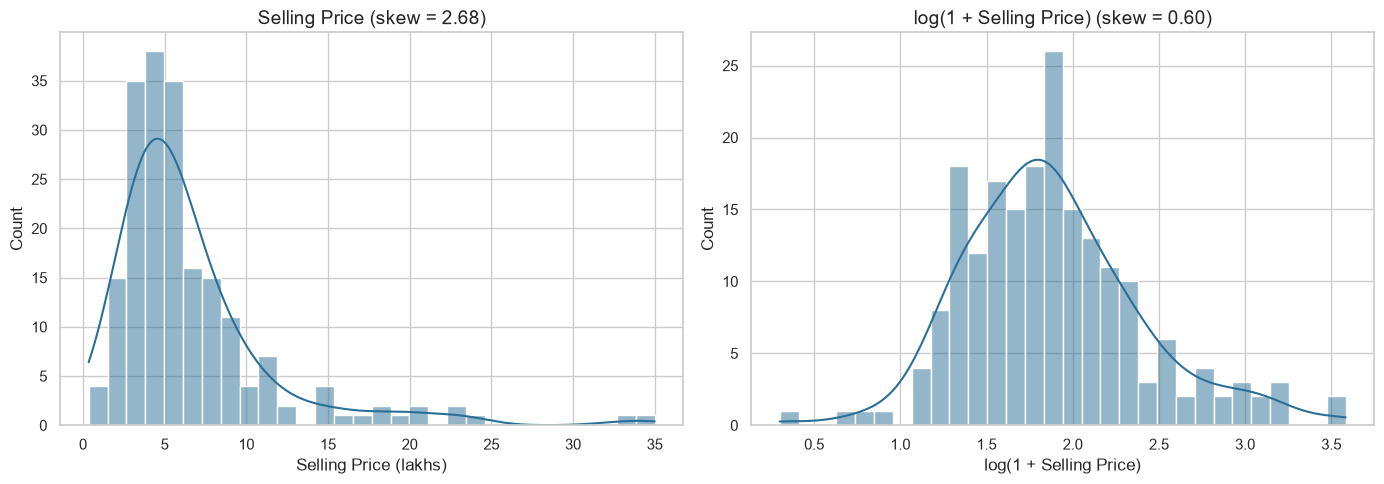

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(car_data["Selling_Price"], kde=True, bins=30, ax=axes[0], color="#2a6f97")
axes[0].set_title(f"Selling Price (skew = {skew(car_data['Selling_Price']):.2f})")
axes[0].set_xlabel("Selling Price (lakhs)")

sns.histplot(np.log1p(car_data["Selling_Price"]), kde=True, bins=30, ax=axes[1], color="#2a6f97")
axes[1].set_title(f"log(1 + Selling Price) (skew = {skew(np.log1p(car_data['Selling_Price'])):.2f})")
axes[1].set_xlabel("log(1 + Selling Price)")
plt.tight_layout()
plt.show()

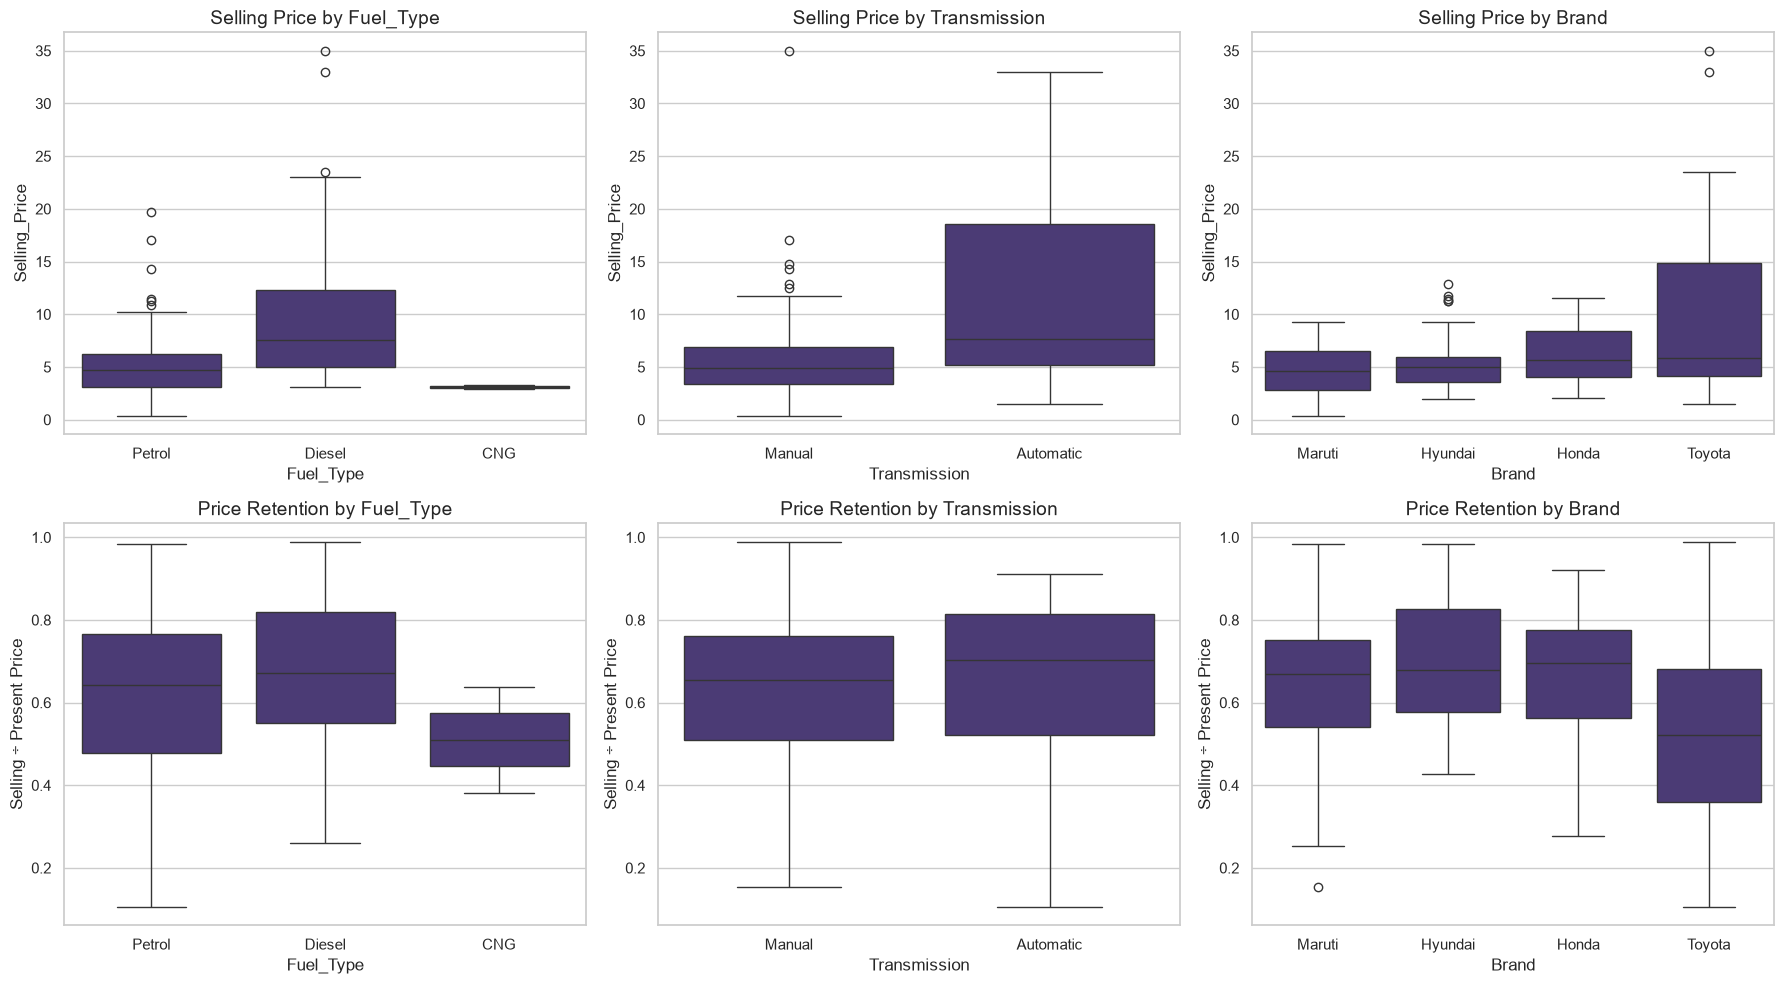

In [26]:
retention = car_data["Selling_Price"] / car_data["Present_Price"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
brand_order = car_data.groupby("Brand")["Selling_Price"].median().sort_values().index

for ax, col in zip(axes[0], ["Fuel_Type", "Transmission", "Brand"]):
    order = brand_order if col == "Brand" else None
    sns.boxplot(data=car_data, x=col, y="Selling_Price", order=order, ax=ax)
    ax.set_title(f"Selling Price by {col}")

for ax, col in zip(axes[1], ["Fuel_Type", "Transmission", "Brand"]):
    order = brand_order if col == "Brand" else None
    sns.boxplot(x=car_data[col], y=retention, order=order, ax=ax)
    ax.set_title(f"Price Retention by {col}")
    ax.set_ylabel("Selling ÷ Present Price")

plt.tight_layout()
plt.show()

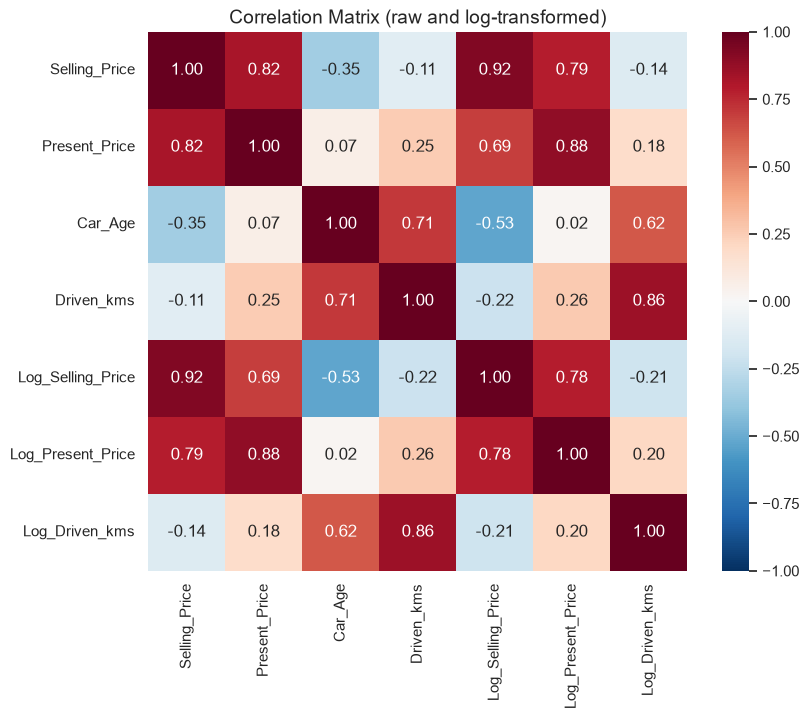

In [27]:
num = car_data[["Selling_Price", "Present_Price", "Car_Age", "Driven_kms"]].copy()
num["Log_Selling_Price"] = np.log1p(num["Selling_Price"])
num["Log_Present_Price"] = np.log1p(num["Present_Price"])
num["Log_Driven_kms"] = np.log1p(num["Driven_kms"])

plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix (raw and log-transformed)")
plt.show()

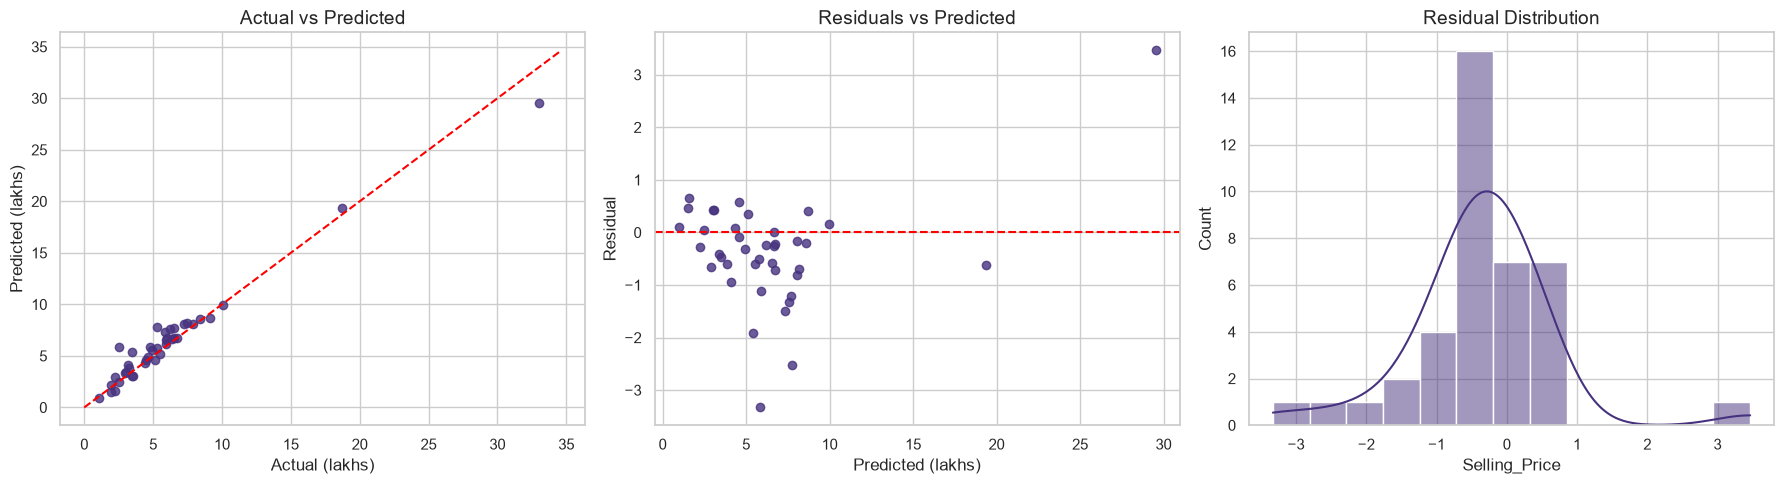

In [57]:
y_pred = final_model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, y_pred, alpha=0.8)
lims = [0, max(y_test.max(), y_pred.max()) * 1.05]
axes[0].plot(lims, lims, "r--")
axes[0].set(xlabel="Actual (lakhs)", ylabel="Predicted (lakhs)", title="Actual vs Predicted")
axes[1].scatter(y_pred, residuals, alpha=0.8)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(xlabel="Predicted (lakhs)", ylabel="Residual", title="Residuals vs Predicted")

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

##  Tuning And Feature Importance

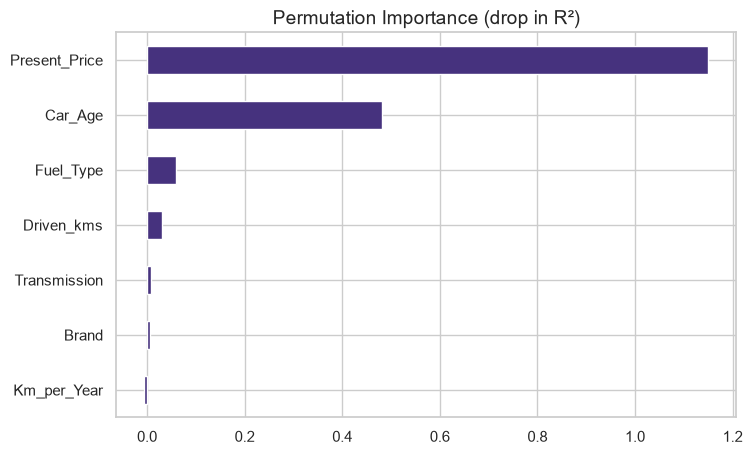

In [59]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Permutation Importance (drop in R²)")
plt.show()

## Insights, Recommendations And Conclusion


## Conclusions

The model predicts used-car prices accurately. Ridge Regression performed best among the four models, explaining approximately 96% of the variation in selling prices on unseen cars (R² = 0.958). It achieved a Mean Absolute Error (MAE) of 0.735 lakhs and a Root Mean Squared Error (RMSE) of 1.083 lakhs. The tree-based models (XGBoost, Gradient Boosting, and Random Forest) performed less well, with RMSE values ranging from 1.7 to 2.3 lakhs.

A car's selling price depends mainly on its original price and age. `Present_Price` was the strongest predictor, followed by `Car_Age`, while the other features contributed relatively little. Although diesel, automatic, and Toyota cars appeared more expensive in the raw price comparisons, their price-retention patterns suggest that these differences largely reflect their original prices rather than a clear premium for fuel type, transmission, or brand. Most groups retained approximately 64–70% of their original prices, while Toyota retained about 52%.

The results show that a simple, regularised linear model can outperform more complex ensemble models on a relatively small dataset. Ridge Regression is suitable for estimating prices of ordinary used cars but is less accurate at the upper end of the price range. In particular, it underpriced the most expensive car by approximately 3 lakhs. Since the test set contains only about 40 cars, these results provide a useful indication of performance but should not be treated as a definitive measure of accuracy.

## Recommendations

### 1. For Sellers and Buyers

- Use the car's original price (`Present_Price`) and age (`Car_Age`) as the main starting points when estimating a fair selling price.
- Compare a vehicle's estimated price with similar listings before making buying or selling decisions.
- Do not assume that diesel fuel, automatic transmission, or a particular brand automatically justifies a higher price. Consider the vehicle's original price and depreciation when interpreting these differences.

### 2. For Dealerships

- Use the model to support quick valuations of ordinary used cars, where prediction errors are generally smaller.
- Have experienced staff review estimates for premium and high-priced vehicles because the model may underestimate their selling prices.
- Investigate Toyota's relatively low price retention further before using this finding to guide purchasing or stocking decisions.

### 3. For Improving the Model

- Collect more training data, particularly for high-priced cars, which are less represented in the current dataset.
- Include additional relevant features, such as vehicle condition, engine size, horsepower, mileage history, and location, where available.
- Evaluate whether features such as `Brand`, `Km_per_Year`, and `Transmission` can be removed without reducing predictive performance.
- Use repeated cross-validation or a larger test set to obtain a more reliable assessment of model performance.
- Continue comparing Ridge Regression with other models as the dataset grows and its range of vehicle characteristics becomes more representative.

### 4. For Deployment

- Deploy the saved Ridge Regression pipeline in a simple web application built with Streamlit or Flask.
- Ensure that users provide the required vehicle details in the correct format and that predictions are displayed in lakhs.
- Record the scikit-learn version and other required dependencies in `requirements.txt` to improve reproducibility and compatibility when loading the saved model.
- Clearly communicate that predictions are estimates and that actual selling prices may vary depending on vehicle condition, market demand, and other factors not captured in the dataset.

## Final Insight

Overall, Ridge Regression is the preferred model for this used-car price prediction project because it achieved the strongest test-set performance among the four models evaluated. The analysis also shows that original price and vehicle age are the most influential factors in estimating resale value. With more representative data, additional vehicle features, and further validation, the model could become a useful decision-support tool for buyers, sellers, and dealerships.
